# 02 · H1: reproducción independiente del pipeline v2 (9 chips del E1)

Se ejecuta **exactamente** el pipeline v2 del equipo (`run_sam_pipeline_v2.py`) sobre los mismos 9 chips, en otra máquina y otro sistema operativo, y se compara chip por chip con el JSON original (`results/referencia_equipo_v2/resultados_reales_v2.json`). Usa la misma llamada de una sola pasada (procesador con puntos, `model(**inputs)`), sin caché.

**Expectativa previa (protocolo R0).** IoU idénticos hasta el cuarto decimal, porque el pipeline es determinista y las versiones de las librerías son las mismas.

**Resultado de la primera ejecución (registrado antes de esta versión del notebook).** Otsu coincidió exactamente en los 9 chips y SAM en 6. En Nigeria, Pakistán y Sri Lanka difirió, y en Sri Lanka la máscara elegida cambió de 97.7 % a 84.8 % de agua. La causa está en el muestreo de prompts: la transformada de distancia tiene empates y `np.argsort` sin orden estable los desempata según la implementación SIMD de la CPU. Esta máquina usa AVX2 (X86_V3); el contenedor original probablemente tenía AVX-512. La sección 3 lo cuantifica, y la versión v2.1 (orden estable) es la que usan los experimentos nuevos.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from inf659sam import config, data
from inf659sam.baseline import auto_prompts, iou_components, normalize_band, otsu_masks, verify_point_labels
from inf659sam.cache import save_json
from inf659sam.sam_utils import SamWrapper
from inf659sam.stats import aggregate

config.setup_runtime(seed=0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9})
sam = SamWrapper()
ref = json.loads((config.RESULTS_DIR / "referencia_equipo_v2" / "resultados_reales_v2.json").read_text(encoding="utf-8"))
ref_chip = {r["chip"]: r for r in ref["per_chip"]}
chips = [c for c in data.first_chip_per_region(data.read_split("valid"))]
print("Chips (regla del E1):", chips)

Entorno: {'seed': 0, 'torch_threads': 2, 'priority': 'baja'}


Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Loading weights:  18%|█▊        | 58/314 [00:00<00:00, 547.67it/s]

Loading weights:  36%|███▌      | 113/314 [00:00<00:00, 336.24it/s]

Loading weights: 100%|██████████| 314/314 [00:00<00:00, 945.95it/s]

Chips (regla del E1): ['Ghana_5079', 'India_1050276', 'Mekong_1149855', 'Nigeria_31096', 'Pakistan_43105', 'Paraguay_305760', 'Somalia_12849', 'Spain_1199913', 'Sri-Lanka_85652', 'USA_826217']


In [2]:
rows, viz = [], {}
for chip in chips:
    d = data.load_chip(chip)
    label = d["label"]
    label_valid = label != -1
    if (~label_valid).mean() > config.NODATA_EXCLUSION_THRESHOLD:
        print(f"[excluido] {chip}: {(~label_valid).mean()*100:.1f} % sin etiqueta")
        continue
    gt = (label == 1) & label_valid
    om = otsu_masks(d["vv"], d["vh"])
    pts, lbs, npos = auto_prompts(om["opened"], om["sensor_valid"], stable=False)  # v2 literal
    rgb = SamWrapper.sar_to_rgb(d["vv"], d["vh"])
    inputs = sam.processor(rgb, input_points=[[pts]], input_labels=[[lbs]], return_tensors="pt")
    with torch.no_grad():
        out = sam.model(**inputs)
    masks = sam.processor.image_processor.post_process_masks(
        out.pred_masks.cpu(), inputs["original_sizes"].cpu(), inputs["reshaped_input_sizes"].cpu())[0]
    scores = out.iou_scores[0, 0].numpy()
    sam_mask = masks[0, int(np.argmax(scores))].numpy().astype(bool)
    r_sam = iou_components(sam_mask, gt, label_valid)
    r_otsu = iou_components(om["opened"], gt, label_valid)
    r_raw = iou_components(om["raw"], gt, label_valid)
    e = ref_chip[chip]
    rows.append({"chip": chip, "IoU_SAM_v2": r_sam["iou"], "IoU_SAM_equipo": e["iou_sam"]["iou"],
                 "IoU_Otsu_abierto": r_otsu["iou"], "IoU_Otsu_equipo": e["iou_threshold_opened"]["iou"],
                 "agua_SAM_pct": 100 * sam_mask[label_valid].mean(), "coords_ok": verify_point_labels(pts, lbs, om["opened"]),
                 "tp": r_sam["tp"], "fp": r_sam["fp"], "fn": r_sam["fn"],
                 "otsu_tp": r_otsu["tp"], "otsu_fp": r_otsu["fp"], "otsu_fn": r_otsu["fn"],
                 "raw_tp": r_raw["tp"], "raw_fp": r_raw["fp"], "raw_fn": r_raw["fn"],
                 "scores": scores.tolist()})
    if chip == "Somalia_12849":
        viz = {"vh": d["vh"], "otsu": om["opened"], "sam": sam_mask, "gt": gt, "valid": label_valid,
               "iou_otsu": r_otsu["iou"], "iou_sam": r_sam["iou"]}
df = pd.DataFrame(rows)
df["dif_SAM"] = df["IoU_SAM_v2"] - df["IoU_SAM_equipo"]
df["dif_Otsu"] = df["IoU_Otsu_abierto"] - df["IoU_Otsu_equipo"]
print("Máxima diferencia absoluta con el equipo: SAM", df["dif_SAM"].abs().max(), "| Otsu", df["dif_Otsu"].abs().max())
df[["chip", "IoU_Otsu_abierto", "IoU_Otsu_equipo", "IoU_SAM_v2", "IoU_SAM_equipo", "agua_SAM_pct", "coords_ok"]].round(4)

[excluido] Ghana_5079: 100.0 % sin etiqueta


Máxima diferencia absoluta con el equipo: SAM 0.001195461443242743 | Otsu 0.0


,chip,IoU_Otsu_abierto,IoU_Otsu_equipo,IoU_SAM_v2,IoU_SAM_equipo,agua_SAM_pct,coords_ok
0,India_1050276,0.4483,0.4483,0.1885,0.1885,97.5641,True
1,Mekong_1149855,0.4963,0.4963,0.1296,0.1296,44.1624,True
2,Nigeria_31096,0.0103,0.0103,0.0035,0.0035,96.3368,True
3,Pakistan_43105,0.0006,0.0006,0.0004,0.0004,21.5114,True
4,Paraguay_305760,0.3724,0.3724,0.1670,0.1670,99.7044,True
5,Somalia_12849,0.1770,0.1770,0.1981,0.1981,96.7214,True
6,Spain_1199913,0.1527,0.1527,0.0358,0.0358,97.3438,True
7,Sri-Lanka_85652,0.0176,0.0176,0.0089,0.0101,84.8212,True
8,USA_826217,0.0561,0.0561,0.0046,0.0046,73.5566,True


In [3]:
agg_sam = aggregate([{"tp": r["tp"], "fp": r["fp"], "fn": r["fn"]} for r in rows])
agg_otsu = aggregate([{"tp": r["otsu_tp"], "fp": r["otsu_fp"], "fn": r["otsu_fn"]} for r in rows])
agg_raw = aggregate([{"tp": r["raw_tp"], "fp": r["raw_fp"], "fn": r["raw_fn"]} for r in rows])
tabla = pd.DataFrame({
    "Otsu sin apertura": [agg_raw["global_iou"], ref["resultados"]["umbral_otsu_sin_apertura"]["global_iou"]],
    "Otsu con apertura": [agg_otsu["global_iou"], ref["resultados"]["umbral_otsu_con_apertura"]["global_iou"]],
    "SAM v2": [agg_sam["global_iou"], ref["resultados"]["sam_con_prompts_automaticos"]["global_iou"]],
}, index=["IoU global (esta corrida)", "IoU global (equipo, v2)"])
print("SAM peor que Otsu con apertura en", int((df["IoU_SAM_v2"] < df["IoU_Otsu_abierto"]).sum()), "de", len(df), "chips")
print("SAM marca > 96 % del soporte como agua en", int((df["agua_SAM_pct"] > 96).sum()), "chips")
save_json({"filas": rows, "agregado": {"sam_v2": agg_sam, "otsu_abierto": agg_otsu, "otsu_crudo": agg_raw},
           "max_dif_abs_iou_sam": float(df["dif_SAM"].abs().max()), "max_dif_abs_iou_otsu": float(df["dif_Otsu"].abs().max()),
           "entorno": config.environment_report()},
          config.RESULTS_DIR / "H1_reproduccion_9chips.json")
tabla.round(6)

SAM peor que Otsu con apertura en 8 de 9 chips
SAM marca > 96 % del soporte como agua en 5 chips


,Otsu sin apertura,Otsu con apertura,SAM v2
IoU global (esta corrida),0.159286,0.187533,0.090878
"IoU global (equipo, v2)",0.159286,0.187533,0.089747


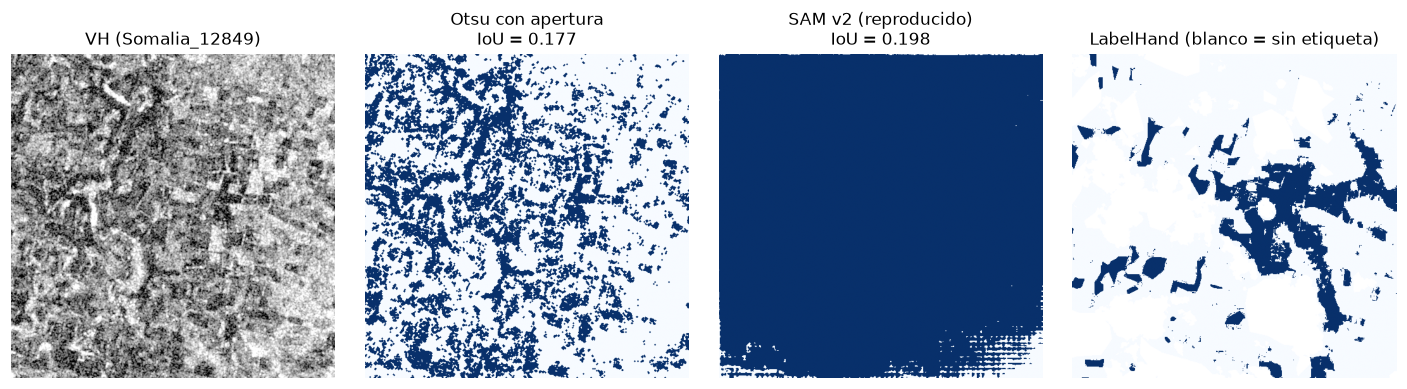

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
axes[0].imshow(normalize_band(viz["vh"]), cmap="gray")
axes[0].set_title("VH (Somalia_12849)")
axes[1].imshow(viz["otsu"], cmap="Blues")
axes[1].set_title(f"Otsu con apertura\nIoU = {viz['iou_otsu']:.3f}")
axes[2].imshow(viz["sam"], cmap="Blues")
axes[2].set_title(f"SAM v2 (reproducido)\nIoU = {viz['iou_sam']:.3f}")
gt_show = np.where(viz["valid"], viz["gt"].astype(float), np.nan)
axes[3].imshow(gt_show, cmap="Blues")
axes[3].set_title("LabelHand (blanco = sin etiqueta)")
for a in axes:
    a.axis("off")
plt.tight_layout()
plt.savefig(config.FIG_DIR / "H1_somalia_reproducido.png")
plt.show()

## 3. Empates en el muestreo de prompts: v2 literal frente a v2.1 (orden estable)

Se cuenta en cuántos chips cambian los puntos al desempatar de forma estable, y cómo cambia el IoU de SAM. Con `stable=True` el resultado ya no depende de la CPU.

In [5]:
from inf659sam.baseline import sample_interior_points

tie_rows = []
for chip in [r["chip"] for r in rows]:
    d = data.load_chip(chip)
    lab = d["label"]
    om = otsu_masks(d["vv"], d["vh"])
    p0, l0, _ = auto_prompts(om["opened"], om["sensor_valid"], stable=False)
    p1, l1, _ = auto_prompts(om["opened"], om["sensor_valid"], stable=True)
    pre = sam.preprocess(SamWrapper.sar_to_rgb(d["vv"], d["vh"]))
    emb = sam.embed(pre["pixel_values"])
    out = {}
    for name, (p, l) in (("v2_literal", (p0, l0)), ("v2.1_estable", (p1, l1))):
        r = sam.decode(emb, p, l, pre["original_sizes"], pre["reshaped_input_sizes"])
        m = r["masks"][int(np.argmax(r["scores"]))]
        out[name] = iou_components(m, lab == 1, lab != -1)
    tie_rows.append({"chip": chip, "prompts_iguales": p0 == p1, "IoU_v2_literal": out["v2_literal"]["iou"],
                     "IoU_v2.1_estable": out["v2.1_estable"]["iou"],
                     "tp_e": out["v2.1_estable"]["tp"], "fp_e": out["v2.1_estable"]["fp"], "fn_e": out["v2.1_estable"]["fn"]})
df_t = pd.DataFrame(tie_rows)
agg_e = aggregate([{"tp": r["tp_e"], "fp": r["fp_e"], "fn": r["fn_e"]} for r in tie_rows])
print(f"Chips con prompts distintos: {int((~df_t['prompts_iguales']).sum())} de {len(df_t)}")
print(f"IoU global SAM v2.1 (estable) en los 9 chips: {agg_e['global_iou']:.4f}  | v2 literal en esta máquina: {agg_sam['global_iou']:.4f}  | equipo: 0.0897")
df_t[["chip", "prompts_iguales", "IoU_v2_literal", "IoU_v2.1_estable"]].round(4)

Chips con prompts distintos: 6 de 9
IoU global SAM v2.1 (estable) en los 9 chips: 0.0893  | v2 literal en esta máquina: 0.0909  | equipo: 0.0897


,chip,prompts_iguales,IoU_v2_literal,IoU_v2.1_estable
0,India_1050276,False,0.1885,0.1882
1,Mekong_1149855,False,0.1296,0.1289
2,Nigeria_31096,False,0.0035,0.0035
3,Pakistan_43105,False,0.0004,0.0004
4,Paraguay_305760,True,0.1670,0.1670
5,Somalia_12849,False,0.1981,0.1981
6,Spain_1199913,True,0.0358,0.0358
7,Sri-Lanka_85652,False,0.0089,0.0100
8,USA_826217,True,0.0046,0.0046


## 4. Memoria pico del pipeline SAR

Este notebook corre en un kernel nuevo que solo ejecutó el pipeline v2 (carga de SAM y 9 pasadas completas). Su pico de memoria (*peak working set* de Windows) es la memoria del pipeline SAR que el E1 dejó como `[pendiente]`.

In [6]:
import psutil

mi = psutil.Process().memory_info()
pico = getattr(mi, "peak_wset", mi.rss) / 2**30
print(f"Pico de memoria del proceso (pipeline SAR, 9 chips): {pico:.2f} GiB  | RSS actual: {mi.rss / 2**30:.2f} GiB")
save_json({"filas": rows, "agregado": {"sam_v2": agg_sam, "otsu_abierto": agg_otsu, "otsu_crudo": agg_raw},
           "max_dif_abs_iou_sam": float(df["dif_SAM"].abs().max()), "max_dif_abs_iou_otsu": float(df["dif_Otsu"].abs().max()),
           "empates": tie_rows, "agregado_v21_estable": agg_e, "pico_memoria_gib": pico,
           "entorno": config.environment_report()},
          config.RESULTS_DIR / "H1_reproduccion_9chips.json")

Pico de memoria del proceso (pipeline SAR, 9 chips): 2.52 GiB  | RSS actual: 1.02 GiB
